# Fase G: ensamble fusionado, calibración y cortes

Criterio fijado antes en `README.md` (fase G). F: XGBoost con *b* = 0, podadas + dinámica. S: XGBoost con *b* = 30, podadas. Scores dejando una persona fuera de las 5 semillas, fusionados como sigmoide(media de logit). Se calibra si Platt o isotónica bajan el Brier al menos 0.002; luego se reajustan los cortes con las reglas de E9b.

In [1]:
import os, json
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import brier_score_loss
from experiments import calibration as C
from experiments import e9b as E
from experiments.modeling import evaluate, persistence_score
from pipelines.labels.build_windows import seconds

SEEDS = range(5)
d8 = pd.read_parquet("data/reports/e8d_scores.parquet")
b30 = pd.read_parquet("data/reports/e4b_scores_b30.parquet")
keep = ["user_id", "t_utc", "day", "s_60", "f_60", "prof_pf", "prof_ps"]
rf = pd.read_csv("data/processed/real_features.csv", usecols=keep + ["y_f"])
rs = pd.read_csv("data/processed/real_features_b30.csv", usecols=keep + ["y_s"])
seeds = {"F": {s: d8[f"y_f|+ all dynamics|{s}"].to_numpy() for s in SEEDS},
         "S": {s: b30[f"y_s|{s}"].to_numpy() for s in SEEDS}}
frames = {"F": (rf, "y_f"), "S": (rs, "y_s")}

def auc(frame, label, score):
    return evaluate(frame[label].astype(int), score, frame["user_id"], persistence_score(frame), n_boot=200)

rows = {}
for pat, (frame, label) in frames.items():
    merged = C.merge_probs(seeds[pat])
    r = auc(frame, label, merged)
    per_seed = [auc(frame, label, seeds[pat][s])["auc_median"] for s in SEEDS]
    rows[pat] = {"merged AUC": r["auc_median"], "CI95": "%.3f-%.3f" % tuple(r["auc_median_ci95"]),
                 "single seeds (min-max)": "%.3f-%.3f" % (min(per_seed), max(per_seed)),
                 "representative seed (fallback)": C.representative_seed(seeds[pat])}
pd.DataFrame(rows).T

,merged AUC,CI95,single seeds (min-max),representative seed (fallback)
F,0.709916,0.676-0.729,0.693-0.715,1
S,0.953435,0.923-0.970,0.946-0.954,2


## Calibración

Calibradores ajustados dejando una persona fuera sobre los scores de las demás.

In [2]:
cal, scores = {}, {}
for pat, (frame, label) in frames.items():
    y = frame[label].astype(int).to_numpy()
    raw = C.merge_probs(seeds[pat])
    variants = {"raw": raw,
                "platt": C.lopo_calibrate(raw, y, frame["user_id"], "platt"),
                "isotonic": C.lopo_calibrate(raw, y, frame["user_id"], "isotonic")}
    scores[pat] = variants
    for name, s in variants.items():
        cal[(pat, name)] = {"Brier": brier_score_loss(y, s), "ECE": C.ece(y, s),
                            "mean score": s.mean(), "positive rate": y.mean(),
                            "AUC (median per person)": auc(frame, label, s)["auc_median"]}
caltab = pd.DataFrame(cal).T
caltab.round(4)

Brier     ECE  mean score  positive rate  AUC (median per person)
F raw       0.1629  0.0520      0.2129         0.2649                   0.7099
  platt     0.1595  0.0138      0.2604         0.2649                   0.7099
  isotonic  0.1603  0.0211      0.2588         0.2649                   0.7099
S raw       0.0601  0.0063      0.1684         0.1715                   0.9534
  platt     0.0605  0.0067      0.1722         0.1715                   0.9534
  isotonic  0.0607  0.0059      0.1720         0.1715                   0.9541

In [3]:
choice = {}
for pat in frames:
    raw_brier = caltab.loc[(pat, "raw"), "Brier"]
    best = min(("platt", "isotonic"), key=lambda m: caltab.loc[(pat, m), "Brier"])
    gain = raw_brier - caltab.loc[(pat, best), "Brier"]
    choice[pat] = best if gain >= 0.002 else "raw"
    print(f"{pat}: best calibrator {best}, Brier gain {gain:.4f} -> use {choice[pat]}")

F: best calibrator platt, Brier gain 0.0034 -> use platt
S: best calibrator platt, Brier gain -0.0005 -> use raw


## Curva de calibración

Proporción observada de positivos frente al score medio, en 10 bins (solo bins con 20 puntos o más). La diagonal es la calibración perfecta.

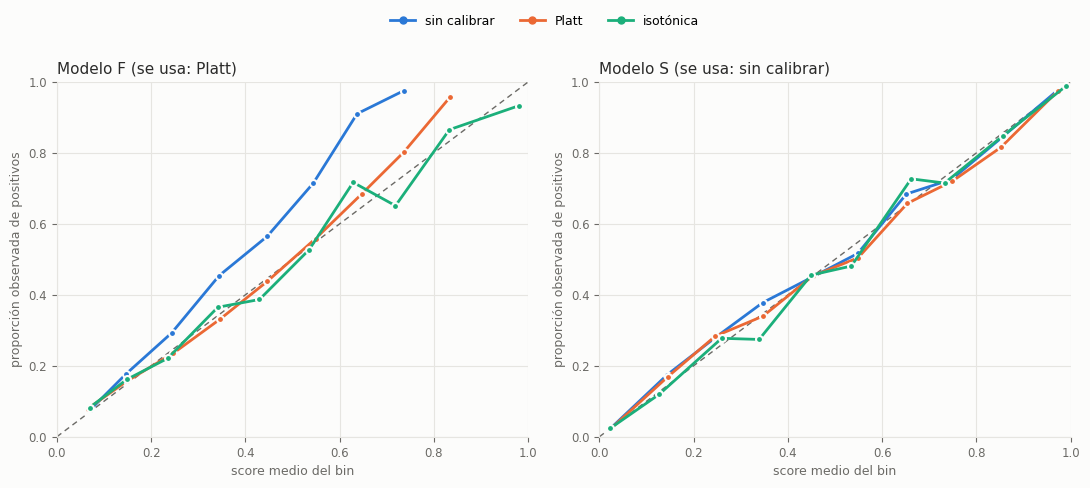

In [4]:
COLORS = {"raw": "#2a78d6", "platt": "#eb6834", "isotonic": "#1baf7a"}  # validated, light surface
LABELS = {"raw": "sin calibrar", "platt": "Platt", "isotonic": "isotónica"}
INK, MUTED, GRID = "#2b2b2a", "#6b6a66", "#e6e5e1"
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), facecolor="#fcfcfb")
for ax, pat in zip(axes, frames):
    frame, label = frames[pat]
    y = frame[label].astype(int).to_numpy()
    ax.set_facecolor("#fcfcfb")
    ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls=(0, (4, 3)))
    for name, s in scores[pat].items():
        idx = np.minimum((s * 10).astype(int), 9)
        pts = pd.DataFrame({"b": idx, "s": s, "y": y}).groupby("b").agg(s=("s", "mean"), y=("y", "mean"), n=("y", "size"))
        pts = pts[pts.n >= 20]
        ax.plot(pts.s, pts.y, color=COLORS[name], lw=2, marker="o", ms=5, mec="#fcfcfb", mew=1.5)
    ax.set_title(f"Modelo {pat} (se usa: {LABELS[choice[pat]]})", loc="left", fontsize=11, color=INK)
    ax.set_xlabel("score medio del bin", fontsize=9, color=MUTED)
    ax.set_ylabel("proporción observada de positivos", fontsize=9, color=MUTED)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.grid(color=GRID, lw=0.8); ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=8.5)
handles = [plt.Line2D([], [], color=COLORS[n], lw=2, marker="o", ms=5, label=LABELS[n]) for n in COLORS]
fig.legend(handles=handles, loc="upper center", ncol=3, frameon=False, fontsize=9, bbox_to_anchor=(0.5, 1.02))
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig("data/reports/g_calibration.png", dpi=150, bbox_inches="tight")
plt.show()

## Cortes reajustados (reglas de E9b)

In [5]:
ff = rf[["user_id", "t_utc", "day", "y_f"]].assign(p_f=scores["F"][choice["F"]])
ss = rs[["user_id", "t_utc", "y_s"]].assign(p_s=scores["S"][choice["S"]])
df = ff.merge(ss, on=["user_id", "t_utc"], how="inner")
df["t"] = seconds(pd.to_datetime(df["t_utc"]))
df = df.sort_values(["user_id", "t"]).reset_index(drop=True)
sweeps, chosen = {}, {}
for pat, col in (("F", "p_f"), ("S", "p_s")):
    cuts = np.unique(np.quantile(df[col], np.linspace(0.30, 0.995, 80)))
    sweeps[pat] = E.sweep(df, pat, cuts)
    chosen[pat] = E.choose(sweeps[pat])
pick = pd.DataFrame({p: sweeps[p].set_index("c").loc[c].to_dict() | {"c": c, "meets both": ok}
                     for p, (c, ok) in chosen.items()}).T
given = E.simulate_joint(df, chosen["F"][0], chosen["S"][0])
per_day = pd.Series(given != "").groupby([df.user_id.to_numpy(), df.day.to_numpy()]).sum()
print(f"{len(df)} common points; joint total per day: mean {per_day.mean():.2f}, "
      f"p90 {per_day.quantile(.9):.0f}, max {per_day.max():.0f}")
pick[["c", "meets both", "precision", "episode_sensitivity", "point_coverage", "per_day_mean", "per_day_p90"]].round(3)

16233 common points; joint total per day: mean 8.42, p90 13, max 18


,c,meets both,precision,episode_sensitivity,point_coverage,per_day_mean,per_day_p90
F,0.446273,True,0.506143,0.247039,0.48093,2.481707,6.0
S,0.241574,True,0.518936,0.910088,0.872432,5.957317,10.0


## Guardar

Calibrador de producción ajustado con todos los scores dejando una persona fuera.

In [6]:
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
final_cal = {}
for pat, (frame, label) in frames.items():
    raw = C.merge_probs(seeds[pat]); y = frame[label].astype(int).to_numpy()
    if choice[pat] == "platt":
        lr = LogisticRegression(C=1e6).fit(C.logit(raw)[:, None], y)
        final_cal[pat] = {"method": "platt", "a": float(lr.coef_[0, 0]), "b": float(lr.intercept_[0])}
    elif choice[pat] == "isotonic":
        iso = IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip").fit(raw, y)
        final_cal[pat] = {"method": "isotonic", "x": iso.X_thresholds_.tolist(), "y": iso.y_thresholds_.tolist()}
    else:
        final_cal[pat] = {"method": "raw"}
out = {"merged": rows, "calibration": {f"{p}|{m}": v for (p, m), v in cal.items()}, "choice": choice,
       "calibrator": final_cal, "cutoffs": {p: {"c": c, "meets_both": ok} for p, (c, ok) in chosen.items()},
       "at_cutoff": pick.to_dict("index"),
       "joint_per_day": {"mean": float(per_day.mean()), "p90": float(per_day.quantile(.9))}}
Path("data/reports/g_calibration.json").write_text(json.dumps(out, indent=2, default=float))
print("-> data/reports/g_calibration.json")

-> data/reports/g_calibration.json


## Nota posterior (2026-10-22)

El corte de S de producción es el de esta regla (0.2416). El de F cambió después: tras E1d, el corte de F pasó al máximo F1 agrupado sobre estos mismos scores, **0.3024** en la escala de Platt (`experiments/cutoff_f1.py`; README §8.4). El valor 0.446 de arriba es el de la regla de E9b.